# TP NEAT - NeuroEvolution of Augmenting Topologies

**Objectifs du TP:**
1. Découvrir l'algorithme NEAT (NeuroEvolution of Augmenting Topologies)
2. Implémenter la fonction de fitness pour le problème XOR
3. Lancer l'évolution sans spéciation
4. Explorer et comprendre les hyperparamètres
5. Implémenter la fonction de spéciation
6. Proposer des améliorations

**Ressources:**
- 📄 [Article original de Stanley & Miikkulainen (2002)](https://nn.cs.utexas.edu/downloads/papers/stanley.ec02.pdf)
- 🎥 [Vidéo explicative](https://www.youtube.com/watch?v=qv6UVOQ0F44)

**Note:** Le TP est exploratoire, laissez vous guider par votre curiosité :)

---

## Partie 1 : Découverte de NEAT

NEAT (NeuroEvolution of Augmenting Topologies) est un algorithme évolutif qui fait évoluer à la fois la **topologie** (structure) et les **poids** des réseaux de neurones.

**Principes clés:**
- Commence avec des réseaux simples (peu ou pas de connexions)
- Ajoute progressivement de la complexité par mutations structurelles
- Utilise un système d'innovation pour suivre l'historique des mutations
- Emploie la spéciation pour protéger les innovations

**Types de mutations:**
1. **Mutations de poids** : modification des poids des connexions existantes
2. **Mutations de biais** : modification des biais des neurones
3. **Ajout de connexion** : création d'une nouvelle connexion entre deux neurones
4. **Ajout de neurone** : insertion d'un nouveau neurone sur une connexion existante

### 1.1 Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from neat_classes import *
from neat_evolution import *

### 1.2 Exploration des classes NEAT

Avant de commencer, explorons rapidement les principales classes.

**💡 Astuce:** Pour plus d'exemples d'utilisation des classes (`Node`, `Connection`, `Genome`, etc.), consultez le notebook `neat_notebook.ipynb` qui contient de nombreux exemples détaillés et cas d'usage.

╔═══════════════════════════════════════════════╗
║ Genome ID: 0                                  ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  0                                  ║
║   Outputs: 1                                  ║
║   Total:   3                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   2                                 ║
║   Disabled: 0                                 ║
║   Total:    2                                 ║
╚═══════════════════════════════════════════════╝

Noeuds:
  [0] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [1] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [2] Node(type=output, activation=sigmoid, bias=0.00, layer=1.00, value=0.00)

Conne

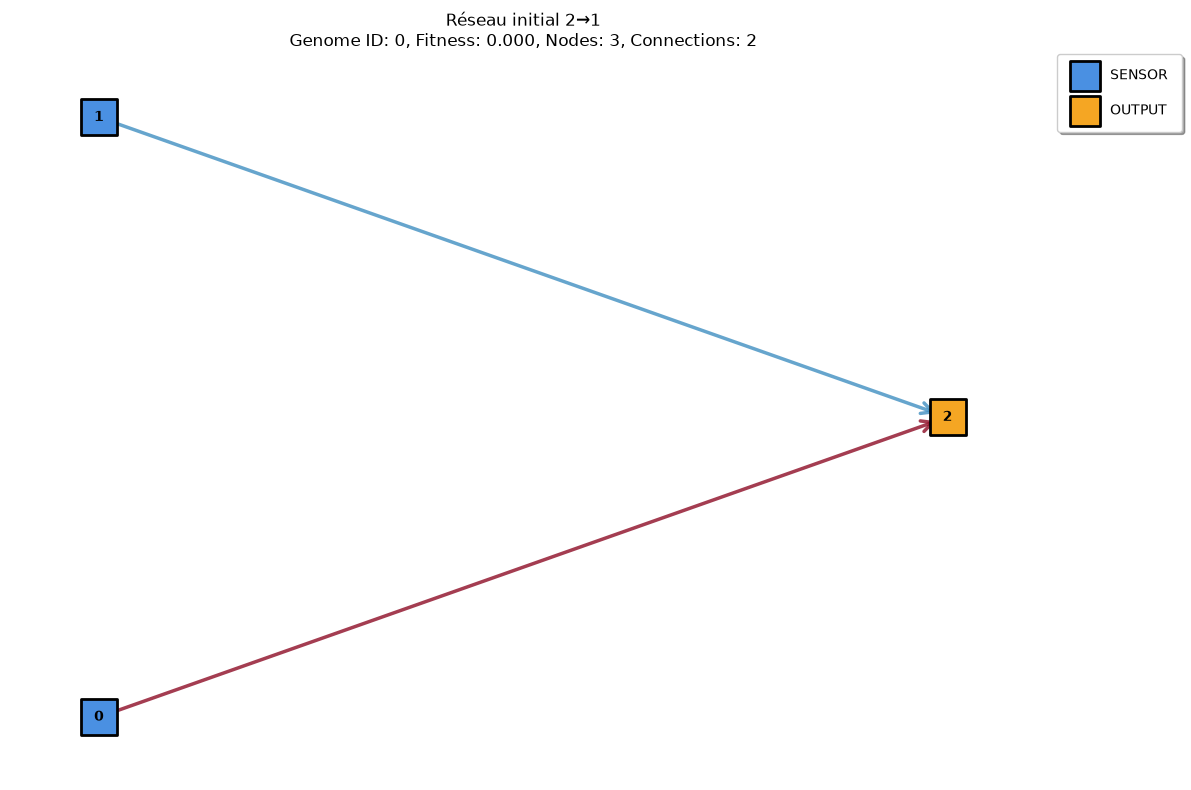

In [2]:
# Créer un génome simple : 2 entrées -> 1 sortie
simple_genome = create_initial_genome(
    genome_id=0,
    num_inputs=2,
    num_outputs=1,
    fully_connected=True
)

print(simple_genome)
print("\nNoeuds:")
for i, node in enumerate(simple_genome.nodes):
    print(f"  [{i}] {node}")
    
print("\nConnexions:")
for conn in simple_genome.connections:
    print(f"  {conn}")

# Visualiser le réseau
visualize_genome(simple_genome, title="Réseau initial 2→1")

### 1.3 Test du forward pass

Testons comment le réseau propage l'information:

In [3]:
# Tester plusieurs entrées
test_inputs = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
]

print("Test du forward pass:")
print("-" * 40)
for inputs in test_inputs:
    output = simple_genome.forward_pass(inputs)
    print(f"Entrées: {inputs} -> Sortie: {output[0]:.4f}")

Test du forward pass:
----------------------------------------
Entrées: [0.0, 0.0] -> Sortie: 0.5000
Entrées: [0.0, 1.0] -> Sortie: 0.2267
Entrées: [1.0, 0.0] -> Sortie: 0.8568
Entrées: [1.0, 1.0] -> Sortie: 0.6369


---
## Partie 2 : Problème XOR - Implémentation de la fitness

Le problème XOR (ou exclusif) est un problème classique en apprentissage automatique. C'est un problème **non linéairement séparable**, ce qui signifie qu'on ne peut pas le résoudre avec un simple perceptron.

**Table de vérité XOR:**
```
| A | B | A XOR B |
|---|---|----------|
| 0 | 0 |    0     |
| 0 | 1 |    1     |
| 1 | 0 |    1     |
| 1 | 1 |    0     |
```

In [4]:
# Dataset XOR
XOR_INPUTS = np.array([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
])

XOR_OUTPUTS = np.array([
    [0.0],
    [1.0],
    [1.0],
    [0.0]
])

### ⚠️ EXERCICE 1 : Implémenter la fonction de fitness

Votre première tâche est d'implémenter la fonction `evaluate_xor` qui calcule la fitness d'un génome sur le problème XOR.

**Objectif:** La fonction doit retourner une valeur entre 0.0 et 1.0, où 1.0 représente une solution parfaite.

**Indice:** Utilisez la Mean Absolute Error (MAE) pour mesurer l'écart entre les prédictions et les cibles, puis convertissez-la en fitness.

In [5]:
def evaluate_xor(genome: Genome) -> float:
    """
    Évalue un génome sur le problème XOR.
    
    Args:
        genome: Le génome à évaluer
        
    Returns:
        fitness: Score de fitness entre 0.0 et 1.0 (plus élevé = meilleur)
    """
    erreurs = 0.0
    
    for input, output in zip(XOR_INPUTS, XOR_OUTPUTS) :
        sortie = genome.forward_pass(input)
        erreurs += abs(output[0] - sortie[0])
    mae = erreurs / len(XOR_INPUTS) 
    return 1 - mae
    


### Test de votre fonction de fitness

Testez votre fonction sur le génome simple créé précédemment:

In [6]:
# Tester la fonction de fitness
fitness = evaluate_xor(simple_genome)
print(f"Fitness du réseau initial: {fitness:.6f}")
print("\nDétails des prédictions:")
print("-" * 50)
for i, (inputs, target) in enumerate(zip(XOR_INPUTS, XOR_OUTPUTS)):
    output = simple_genome.forward_pass(inputs.tolist())
    error = abs(output[0] - target[0])
    print(f"Exemple {i+1}: {inputs} -> Prédit: {output[0]:.4f}, Attendu: {target[0]:.1f}, Erreur: {error:.4f}")

Fitness du réseau initial: 0.486648

Détails des prédictions:
--------------------------------------------------
Exemple 1: [0. 0.] -> Prédit: 0.5000, Attendu: 0.0, Erreur: 0.5000
Exemple 2: [0. 1.] -> Prédit: 0.2267, Attendu: 1.0, Erreur: 0.7733
Exemple 3: [1. 0.] -> Prédit: 0.8568, Attendu: 1.0, Erreur: 0.1432
Exemple 4: [1. 1.] -> Prédit: 0.6369, Attendu: 0.0, Erreur: 0.6369


---
## Partie 3 : Évolution sans spéciation

Maintenant que nous avons notre fonction de fitness, lançons une première évolution **sans spéciation** pour voir comment NEAT fonctionne.

### 3.1 Configuration des hyperparamètres

In [7]:
# Paramètres de l'évolution
POPULATION_SIZE = 100
NUM_EPOCHS = 50
SURVIVAL_RATE = 0.5  # 50% des individus survivent
KEEP_BEST = 0       # Nombre d'élites conservés sans mutation

# Configuration des mutations
mutation_config = MutationConfig(
    # Mutations des noeuds
    prob_mutate_activation=0.01,
    prob_mutate_bias=0.2,
    bias_mutation_power=0.3,
    bias_replace_rate=0.01,
    
    # Mutations des connexions
    prob_mutate_weight=0.8,
    weight_mutation_power=0.5,
    weight_replace_rate=0.1,
    prob_toggle_connection=0.01,
    
    # Mutations structurelles
    prob_add_connection=0.01,
    prob_add_node=0.005,
    
    # Limites
    bias_min=-1.0,
    bias_max=1.0,
    weight_min=-1.0,
    weight_max=1.0
)

print("Configuration de l'évolution:")
print(f"  Population: {POPULATION_SIZE}")
print(f"  Époques: {NUM_EPOCHS}")
print(f"  Taux de survie: {SURVIVAL_RATE*100:.0f}%")
print(f"  Élitisme: {KEEP_BEST} meilleurs individus")
print(f"\nMutations structurelles:")
print(f"  Ajout connexion: {mutation_config.prob_add_connection*100:.0f}%")
print(f"  Ajout noeud: {mutation_config.prob_add_node*100:.0f}%")

Configuration de l'évolution:
  Population: 100
  Époques: 50
  Taux de survie: 50%
  Élitisme: 0 meilleurs individus

Mutations structurelles:
  Ajout connexion: 1%
  Ajout noeud: 0%


### ⚠️ EXERCICE 2 : Lancer l'évolution sans spéciation

Utilisez la fonction `evolve_population` avec les paramètres suivants:
- `use_species=False` (pas de spéciation)
- `crossover_prob=0.2` (20% de crossover)

In [8]:

history = evolve_population(
    evaluate_fn =evaluate_xor,
    num_inputs=2,
    num_outputs=1,
    population_size=POPULATION_SIZE,
    num_epochs=NUM_EPOCHS,
    survival_rate=SURVIVAL_RATE,
    keep_best=KEEP_BEST,
    crossover_prob=0.2,
    use_species=False
)
  # Remplacer par votre code

DÉBUT DE L'ÉVOLUTION

Époque   0/50:
  Best:   0.557022 | Nodes:  3 | Conn:  2
  Median: 0.500255
  Temps évaluation: 6.69 ms
  Temps reproduction: 29.84 ms

Époque   5/50:
  Best:   0.631021 | Nodes:  4 | Conn:  5
  Median: 0.567390
  Temps évaluation: 9.13 ms
  Temps reproduction: 58.69 ms

Époque  10/50:
  Best:   0.684570 | Nodes:  4 | Conn:  5
  Median: 0.605326
  Temps évaluation: 32.45 ms
  Temps reproduction: 35.76 ms

Époque  15/50:
  Best:   0.740729 | Nodes:  5 | Conn:  7
  Median: 0.644641
  Temps évaluation: 2.32 ms
  Temps reproduction: 12.61 ms

Époque  20/50:
  Best:   0.746600 | Nodes:  5 | Conn:  7
  Median: 0.712229
  Temps évaluation: 4.76 ms
  Temps reproduction: 18.13 ms

Époque  25/50:
  Best:   0.749621 | Nodes:  6 | Conn: 10
  Median: 0.743589
  Temps évaluation: 6.93 ms
  Temps reproduction: 19.19 ms

Époque  30/50:
  Best:   0.749997 | Nodes:  7 | Conn: 12
  Median: 0.748381
  Temps évaluation: 3.85 ms
  Temps reproduction: 17.62 ms

Époque  35/50:
  Best:   

### 3.2 Visualisation des résultats

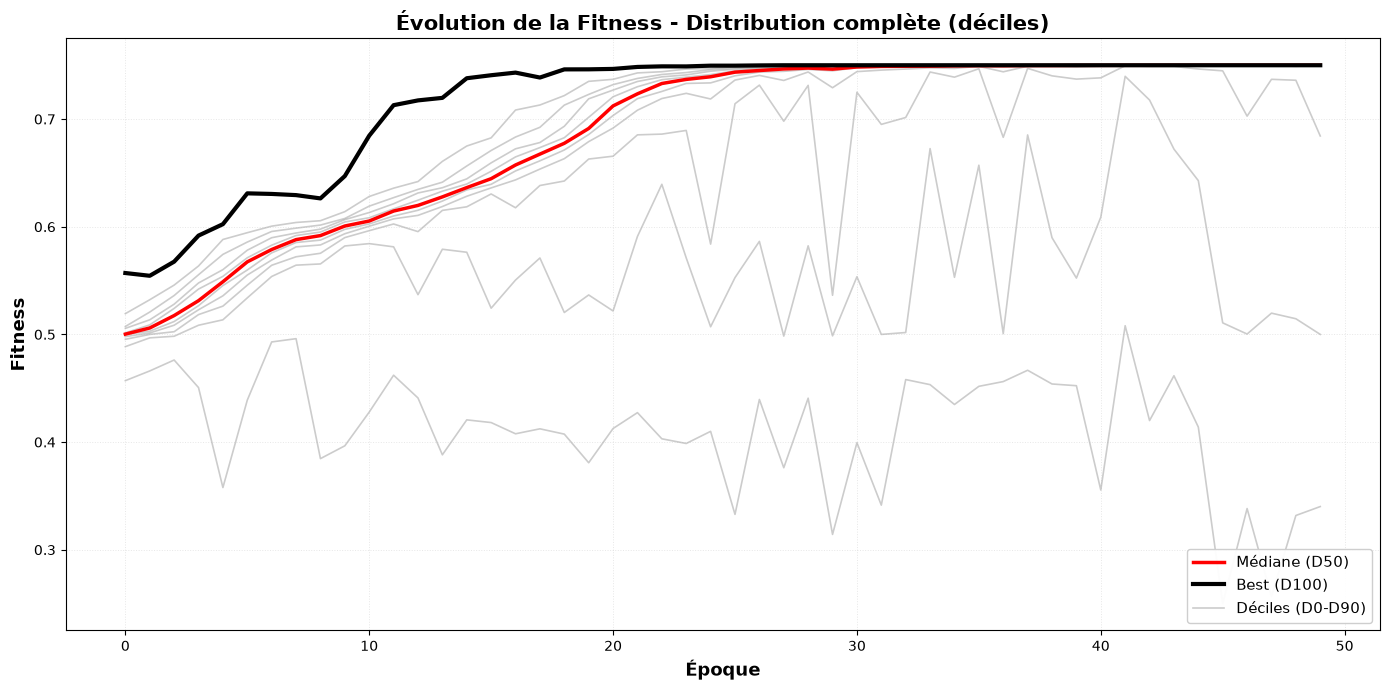

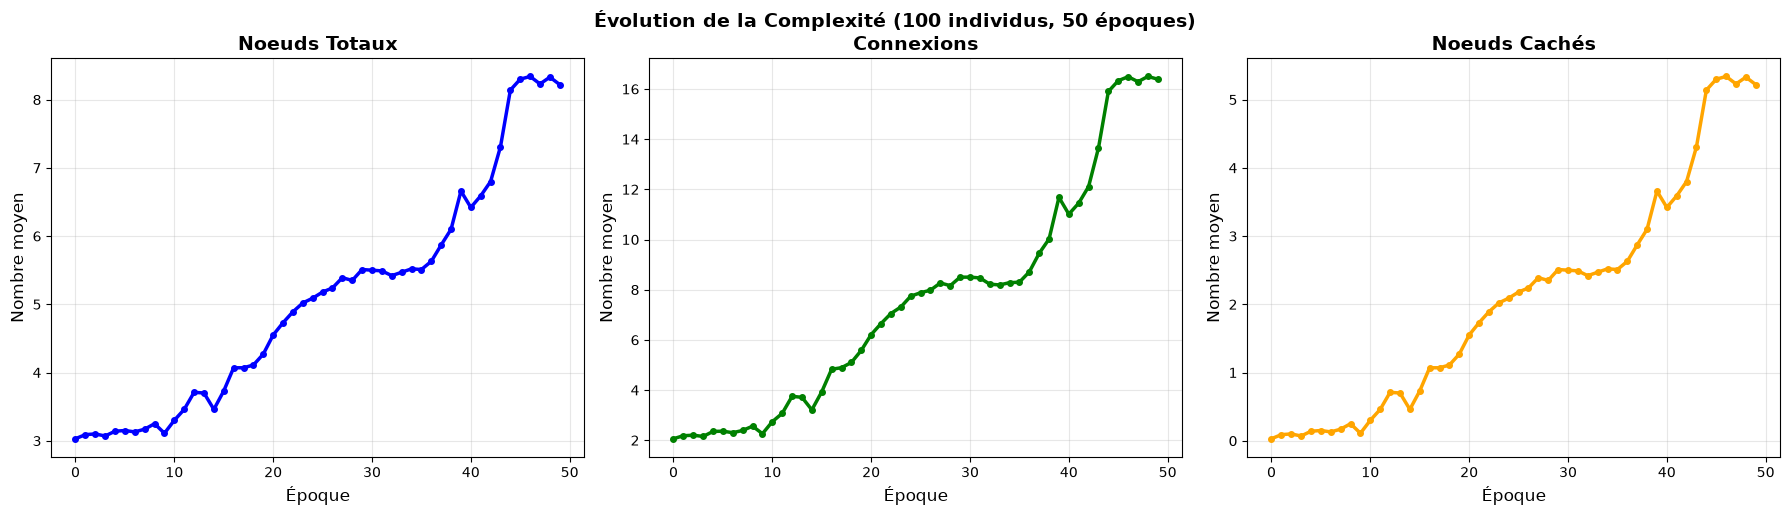

In [9]:
# Visualiser l'évolution
if history is not None:
    plot_evolution_results(
        history=history,
        population_size=POPULATION_SIZE,
        log_scale=False
    )

### 3.3 Analyse du meilleur génome


MEILLEUR GÉNOME TROUVÉ
╔═══════════════════════════════════════════════╗
║ Genome ID: 4543                               ║
║ Fitness:   0.750000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  4                                  ║
║   Outputs: 1                                  ║
║   Total:   7                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   10                                ║
║   Disabled: 3                                 ║
║   Total:    13                                ║
╚═══════════════════════════════════════════════╝

Fitness: 0.750000

Test sur XOR:
--------------------------------------------------
[0. 0.] -> Prédit: 0.0000, Attendu: 0.0
[0. 1.] -> Prédit: 1.0000, Attendu: 1.0
[1. 0.] -> Prédit: 0.0000, Attendu: 1.0
[1. 1.] -> Prédit: 0.

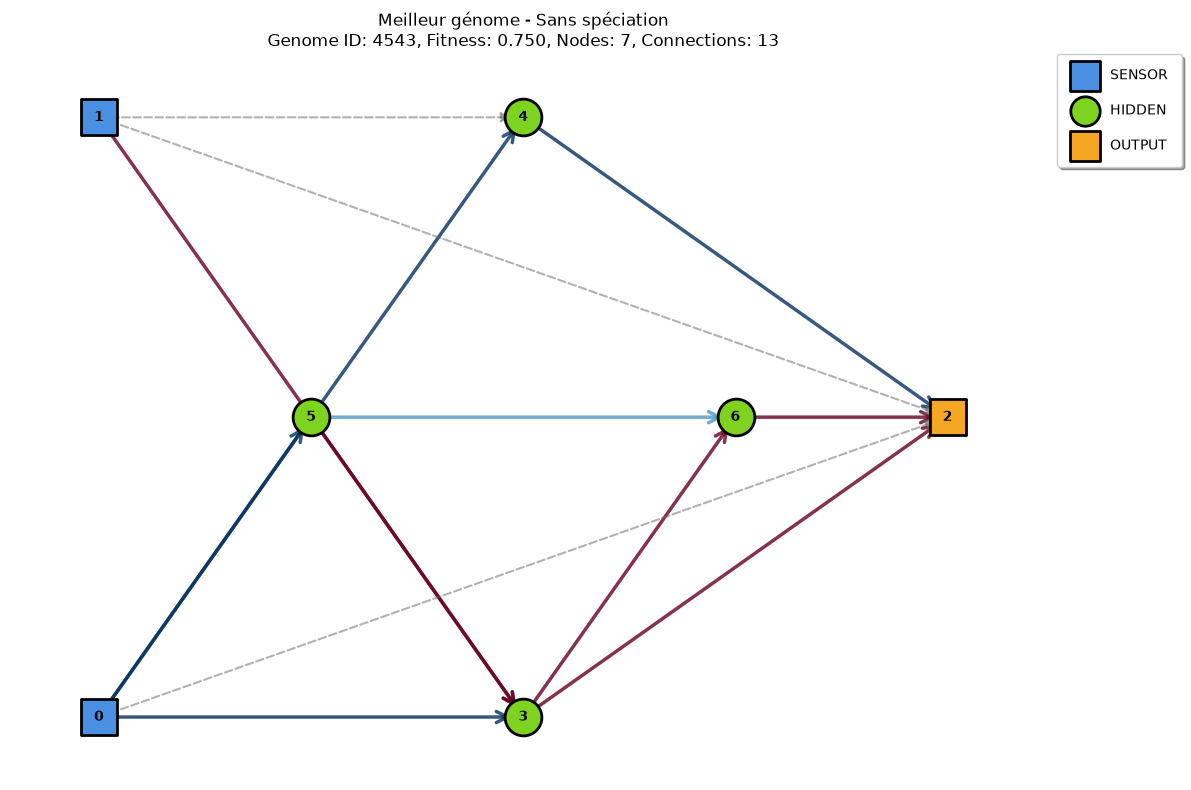

In [10]:
# Analyser le meilleur génome trouvé
if history is not None:
    best_genome = history['best_genome']
    
    print("\n" + "="*70)
    print("MEILLEUR GÉNOME TROUVÉ")
    print("="*70)
    print(best_genome)
    print(f"\nFitness: {best_genome.fitness:.6f}")
    
    # Tester sur tous les exemples XOR
    print("\nTest sur XOR:")
    print("-" * 50)
    for inputs, target in zip(XOR_INPUTS, XOR_OUTPUTS):
        output = best_genome.forward_pass(inputs.tolist())
        print(f"{inputs} -> Prédit: {output[0]:.4f}, Attendu: {target[0]:.1f}")
    
    # Visualiser le réseau
    visualize_genome(best_genome, title="Meilleur génome - Sans spéciation")

**Question de réflexion:**

Qu'observez-vous dans les résultats ? Comment expliquez-vous cela ?

Que pensez vous du meilleur génome obtenu ?

_[Notez vos observations ici]_

---
## Partie 4 : Exploration des hyperparamètres

Les hyperparamètres ont un impact majeur sur l'évolution. Votre objectif est de comprendre comment chaque paramètre influence le processus évolutif.

### ⚠️ EXERCICE 3 : Expérimenter avec les hyperparamètres

**Hyperparamètres à explorer:**

**Paramètres de l'évolution:**
- `POPULATION_SIZE` : Taille de la population
- `NUM_EPOCHS` : Nombre de générations
- `SURVIVAL_RATE` : Proportion de survivants à chaque génération
- `KEEP_BEST` : Nombre d'individus élites (élitisme)
- `fully_connected` : Démarrer avec un réseau connecté ou vide
- `crossover_prob` : Probabilité de reproduction sexuée

**Paramètres de mutation des poids et biais:**
- `prob_mutate_weight` : Probabilité de muter un poids
- `weight_mutation_power` : Amplitude des mutations de poids
- `weight_replace_rate` : Probabilité de remplacer complètement un poids
- `prob_mutate_bias` : Probabilité de muter un biais
- `bias_mutation_power` : Amplitude des mutations de biais
- `weight_min/max`, `bias_min/max` : Limites des valeurs

**Paramètres de mutation structurelle:**
- `prob_add_connection` : Probabilité d'ajouter une connexion
- `prob_add_node` : Probabilité d'ajouter un neurone
- `prob_toggle_connection` : Probabilité d'activer/désactiver une connexion
- `prob_mutate_activation` : Probabilité de changer la fonction d'activation

**Questions ouvertes à explorer:**

1. Comment la taille de la population influence-t-elle la vitesse de convergence et la qualité de la solution ?
2. Quel est l'effet d'une sélection très forte (faible `SURVIVAL_RATE`) vs très faible (fort `SURVIVAL_RATE`) ?
3. Que se passe-t-il si on augmente drastiquement les mutations structurelles ? Et si on les diminue ?
4. Quel est le rôle du crossover ? Comparez une évolution purement asexuée vs fortement sexuée.
5. Comment les limites des poids et biais (`weight_min/max`, `bias_min/max`) affectent-elles l'évolution ?
6. Quelle est l'influence de `weight_mutation_power` et `bias_mutation_power` sur la recherche de solutions ?
7. Partir d'un réseau vide vs fully connected : quelle stratégie est meilleure ? Pourquoi ?
8. Quel impact a l'élitisme (`KEEP_BEST`) sur la convergence ?

**Consignes:**
- Testez au moins 5 configurations différentes
- Pour chaque test, notez : les paramètres changés, la fitness finale, le nombre de générations, la complexité du réseau
- Essayez de comprendre **pourquoi** vous observez ces résultats

In [11]:
history_population = evolve_population(
    evaluate_fn =evaluate_xor,
    num_inputs=2,
    num_outputs=1,
    population_size=50,
    num_epochs=50,
    survival_rate=SURVIVAL_RATE,
    keep_best=KEEP_BEST,
    crossover_prob=0.2,
    use_species=False
)

DÉBUT DE L'ÉVOLUTION

Époque   0/50:
  Best:   0.544317 | Nodes:  3 | Conn:  2
  Median: 0.499947
  Temps évaluation: 5.57 ms
  Temps reproduction: 25.37 ms

Époque   5/50:
  Best:   0.587583 | Nodes:  6 | Conn:  8
  Median: 0.566516
  Temps évaluation: 8.17 ms
  Temps reproduction: 12.10 ms

Époque  10/50:
  Best:   0.635860 | Nodes:  3 | Conn:  2
  Median: 0.607558
  Temps évaluation: 7.46 ms
  Temps reproduction: 18.29 ms

Époque  15/50:
  Best:   0.674671 | Nodes:  4 | Conn:  4
  Median: 0.649470
  Temps évaluation: 1.25 ms
  Temps reproduction: 8.46 ms

Époque  20/50:
  Best:   0.698757 | Nodes:  4 | Conn:  4
  Median: 0.675318
  Temps évaluation: 2.03 ms
  Temps reproduction: 12.33 ms

Époque  25/50:
  Best:   0.703566 | Nodes:  4 | Conn:  4
  Median: 0.689644
  Temps évaluation: 2.98 ms
  Temps reproduction: 12.20 ms

Époque  30/50:
  Best:   0.720112 | Nodes:  4 | Conn:  5
  Median: 0.704005
  Temps évaluation: 6.34 ms
  Temps reproduction: 14.84 ms

Époque  35/50:
  Best:   0.

In [12]:
# Zone d'expérimentation - Testez différentes configurations
# Copiez-collez le code d'évolution de la Partie 3 et modifiez les paramètres




# Analyser le meilleur génome trouvé
if history_population is not None:
    best_genome = history_population['best_genome']
    
    print("\n" + "="*70)
    print("MEILLEUR GÉNOME TROUVÉ")
    print("="*70)
    print(best_genome)
    print(f"\nFitness: {best_genome.fitness:.6f}")
    
    # Tester sur tous les exemples XOR
    # print("\nTest sur XOR:")
    # print("-" * 50)
    # for inputs, target in zip(XOR_INPUTS, XOR_OUTPUTS):
    #     output = best_genome.forward_pass(inputs.tolist())
    #     print(f"{inputs} -> Prédit: {output[0]:.4f}, Attendu: {target[0]:.1f}")
    
    # Visualiser le réseau
   # visualize_genome(best_genome, title="Meilleur génome - Sans spéciation")
  # Remplacer par votre code
  
# EXEMPLE : Test avec une petite population
# POPULATION_SIZE = 50
# ... (modifier les autres paramètres si nécessaire)
# history_test = evolve_population(...)



MEILLEUR GÉNOME TROUVÉ
╔═══════════════════════════════════════════════╗
║ Genome ID: 2460                               ║
║ Fitness:   0.750000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  3                                  ║
║   Outputs: 1                                  ║
║   Total:   6                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   8                                 ║
║   Disabled: 2                                 ║
║   Total:    10                                ║
╚═══════════════════════════════════════════════╝

Fitness: 0.750000


**Tableau de vos expérimentations:**

| Test | Paramètres modifiés | Fitness finale | Générations | Nb noeuds | Nb connexions | Observations |
|------|---------------------|----------------|-------------|-----------|---------------|--------------|
| 1    | POP_SIZE=10000      |  0.999928      | 42          | 6         | 10            | lent
| 2    |10                   |  0.74          |             |           |               |              |
| 3    |epoc = 10            | 0.6            |             |           |               |              |
| 4    | 100                 |  0.75          |             |           |               |              |
| 5    |                     |                |             |           |               |              |

**Synthèse de vos découvertes:**

1. Quel paramètre a le plus d'impact sur la vitesse de convergence ?
   _[Complétez ici]_

2. Quel paramètre a le plus d'impact sur la qualité de la solution ?
   _[Complétez ici]_

3. Comment les mutations structurelles influencent-elles la complexité des réseaux ?
   _[Complétez ici]_

4. Avez-vous trouvé une configuration optimale ? Si oui, laquelle et pourquoi ?
   _[Complétez ici]_

5. Quels compromis avez-vous identifiés (ex: vitesse vs qualité) ?
   _[Complétez ici]_

---
## Partie 5 : Implémentation de la spéciation

La **spéciation** est une innovation clé de NEAT qui permet de:
- Protéger les innovations récentes (qui ont souvent une fitness faible au début)
- Maintenir la diversité de la population
- Éviter la convergence prématurée

### Principe de la spéciation

1. **Distance de compatibilité** : Mesure la différence entre deux génomes
   - Gènes excess (au-delà du dernier gène commun)
   - Gènes disjoint (entre le premier et dernier gène commun)
   - Différence de poids des gènes matching

2. **Seuil de compatibilité** : Si distance < seuil, même espèce

3. **Fitness sharing** : Diviser la fitness par la taille de l'espèce

### ⚠️ EXERCICE 4 : Implémenter speciate_population

Votre tâche est d'implémenter la fonction `speciate_population` dans le fichier `neat_evolution.py`.

**Contexte:**
- La fonction `genome_distance(genome1, genome2, c1, c2, c3)` est déjà implémentée et calcule la distance de compatibilité entre deux génomes
- Chaque génome possède un attribut `species_id` pour stocker son appartenance à une espèce
- Les espèces sont identifiées par des IDs uniques et permanents

**Algorithme à implémenter:**

1. Créer un dictionnaire `species_dict` qui mappe `species_id` → liste de génomes

2. Pour chaque génome de la population:
   - Parcourir tous les représentants d'espèces existantes
   - Calculer la distance avec `genome_distance(genome, representative, c1, c2, c3)`
   - Si `distance < compatibility_threshold`:
     * Ajouter le génome à cette espèce
     * Assigner `genome.species_id = species_id` du représentant
     * Passer au génome suivant (un génome = une seule espèce)
   - Si aucune espèce compatible n'est trouvée:
     * Créer une nouvelle espèce avec `next_species_id`
     * Incrémenter `next_species_id`
     * Ajouter le génome à cette nouvelle espèce
     * Assigner `genome.species_id = new_species_id`

3. Créer les listes de retour:
   - `species_list`: liste de listes de génomes (une par espèce)
   - `new_representatives`: pour chaque espèce, choisir aléatoirement un représentant parmi les membres

4. Retourner `(species_list, new_representatives, next_species_id)`


**💡 Astuce:** N'hésitez pas à tester votre code dans une cellule à part. Les humains créent des bugs. Acceptez l'axiome : "Je suis humain, je vais créer des bugs" :)

### 5.1 Évolution avec spéciation

In [13]:
# Lancer l'évolution AVEC spéciation
history_with_species = evolve_population(
    evaluate_fn=evaluate_xor,
    num_inputs=2,
    num_outputs=1,
    population_size=POPULATION_SIZE,
    num_epochs=NUM_EPOCHS,
    survival_rate=SURVIVAL_RATE,
    keep_best=KEEP_BEST,
    mutation_config=mutation_config,
    fully_connected=False,
    random_seed=42,
    verbose=True,
    verbose_interval=5,
    early_stop_fitness=0.999,
    use_species=True,  # ACTIVER LA SPÉCIATION
    c1=1.0,
    c2=1.0,
    c3=0.4,
    compatibility_threshold=3.0,
    crossover_prob=0.75
)

DÉBUT DE L'ÉVOLUTION

Époque   0/50:
  Best:   0.500000 | Nodes:  3 | Conn:  0
  Median: 0.500000
  Temps évaluation: 4.78 ms


NameError: name 'species_list' is not defined

### 5.2 Visualisation des résultats avec spéciation

In [ ]:
# Visualiser l'évolution de la fitness
plot_evolution_results(
    history=history_with_species,
    population_size=POPULATION_SIZE,
    log_scale=False
)

# Visualiser l'évolution des espèces
plot_species_evolution(history=history_with_species)

### 5.3 Analyse du meilleur génome

In [ ]:
# Analyser le meilleur génome avec spéciation
best_genome_species = history_with_species['best_genome']

print("\n" + "="*70)
print("MEILLEUR GÉNOME (AVEC SPÉCIATION)")
print("="*70)
print(best_genome_species)
print(f"\nFitness: {best_genome_species.fitness:.6f}")

# Tester sur XOR
print("\nTest sur XOR:")
print("-" * 50)
for inputs, target in zip(XOR_INPUTS, XOR_OUTPUTS):
    output = best_genome_species.forward_pass(inputs.tolist())
    print(f"{inputs} -> Prédit: {output[0]:.4f}, Attendu: {target[0]:.1f}")

# Visualiser le réseau
visualize_genome(best_genome_species, title="Meilleur génome - Avec spéciation")

### 5.4 Comparaison avec/sans spéciation

**Questions:**
1. Quelle méthode converge le plus rapidement ?
2. Quelle méthode trouve la meilleure solution ?
3. Comment évolue la complexité des réseaux dans chaque cas ?
4. Quelle est la différence dans la diversité de la population ?

**Vos observations:**

1. Vitesse de convergence:
   _[Complétez ici]_

2. Qualité de la solution:
   _[Complétez ici]_

3. Évolution de la complexité:
   _[Complétez ici]_

4. Diversité:
   _[Complétez ici]_

### 5.5 Jouez avec les hyperparamètres de la spéciation

Maintenant que vous avez implémenté la spéciation, explorez l'impact de ses hyperparamètres:

**Paramètres à tester:**
- `c1`, `c2`, `c3` : Coefficients de la distance de compatibilité
- `compatibility_threshold` : Seuil pour former une nouvelle espèce

**Questions:**
- Comment le seuil de compatibilité influence-t-il le nombre d'espèces ?
- Quel est l'impact des coefficients c1, c2, c3 sur la formation des espèces ?
- La spéciation change-t-elle l'effet du crossover ?

---
## Partie 6 : Améliorations et créativité

**Soyez curieux, améliorez ce que vous pensez pouvoir être amélioré, faites mieux que votre chargé·e de TD !**


### Idées d'améliorations:

1. **Ajustement dynamique du seuil de compatibilité**
   - Augmenter le seuil si trop d'espèces
   - Diminuer le seuil si trop peu d'espèces

2. **Élitisme par espèce**
   - Garder le meilleur individu de chaque espèce

3. **Stagnation des espèces**
   - Supprimer les espèces qui ne progressent pas pendant N générations

4. **Mutations adaptatives**
   - Ajuster les taux de mutation selon la progression

5. **Problème plus complexe**
   - Tester sur un autre problème (classification, régression)
   - Essayer des datasets plus complexes

6. **Visualisation avancée**
   - Animer l'évolution des réseaux
   - Visualiser la frontière de décision
